## Load the clean sales file and monthly table

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
# Only retail_abroad.xlsx is given, so build sales_clean.csv and monthly.csv from it first
name = "retail_abroad.xlsx"
dates = ["InvoiceDate"]
raw = pd.read_excel(name, parse_dates=dates)
raw = raw.rename(columns={"Invoice": "InvoiceNo", "Price": "UnitPrice"})
raw["InvoiceNo"] = raw["InvoiceNo"].astype(str)
keep = (~raw["InvoiceNo"].str.startswith("C")) & (raw["Quantity"] > 0) & (raw["UnitPrice"] > 0)
clean = raw[keep].dropna(subset=["InvoiceDate"]).copy()
clean["Sales"] = clean["Quantity"] * clean["UnitPrice"]
clean.to_csv("sales_clean.csv", index=False)
clean["Month"] = pd.to_datetime(clean["InvoiceDate"]).dt.to_period("M").astype(str)
monthly = clean.pivot_table("Sales", "Month", "Country", "sum", fill_value=0) / 1000
monthly = monthly[monthly.sum().nlargest(5).index]
monthly.to_csv("monthly.csv")

good = pd.read_csv("sales_clean.csv", parse_dates=dates)
table = pd.read_csv("monthly.csv", index_col=0)
print(good.shape)
print(table.round(1).head())

(44981, 9)
         Netherlands  EIRE  Germany  France  Australia
Month                                                 
2010-12          8.8  10.0     15.2     9.6        1.0
2011-01         26.6  21.9     16.9    17.7        9.0
2011-02         23.0  12.2      9.6     8.5       14.7
2011-03         22.4  22.2     14.4    14.6       17.2
2011-04          3.0   7.6     12.3     5.5        0.8


## Stacked area chart: export sales per month

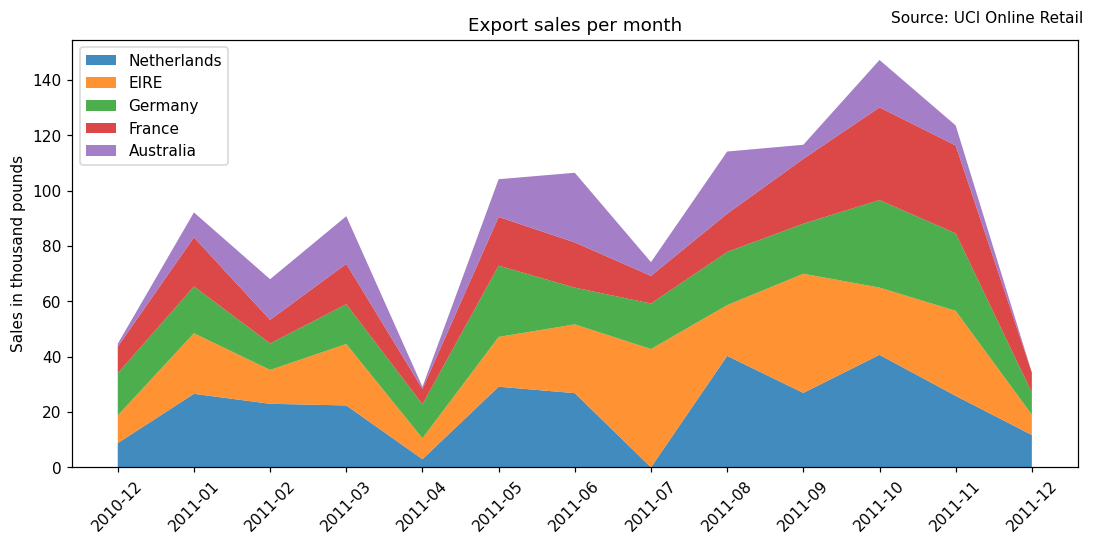

In [2]:
fig, ax = plt.subplots(figsize=(10, 5))
months = table.index.astype(str)
ax.stackplot(months, table.T.values, labels=table.columns, alpha=0.85)
ax.set_title("Export sales per month")
ax.set_ylabel("Sales in thousand pounds")
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="upper left")
src = "Source: UCI Online Retail"
fig.text(0.99, 0.96, src, ha="right")
fig.tight_layout()
plt.show()

## Count orders by weekday and hour with pivot_table

In [3]:
import calendar
days = list(calendar.day_name)
good["Day"] = good["InvoiceDate"].dt.day_name()
good["Hour"] = good["InvoiceDate"].dt.hour
one = good.drop_duplicates("InvoiceNo")
busy = one.pivot_table("InvoiceNo", "Day", "Hour", "count")
busy = busy.reindex(days).fillna(0)
print(busy.sum(axis=1))

Day
Monday       324.0
Tuesday      309.0
Wednesday    371.0
Thursday     439.0
Friday       364.0
Saturday       0.0
Sunday       134.0
dtype: float64


## Heatmap with imshow, colour bar and saved PNG

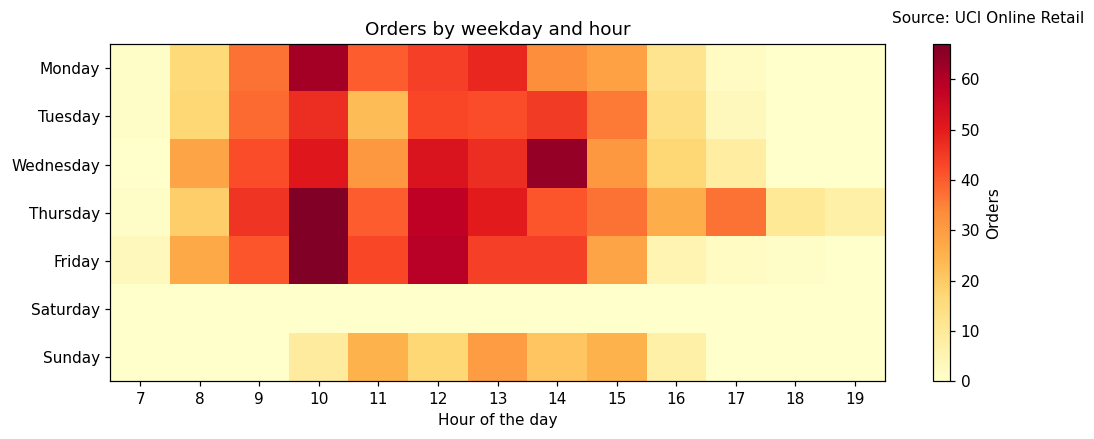

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
img = ax.imshow(busy.values, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(busy.columns)), busy.columns)
ax.set_yticks(range(7), days)
ax.set_title("Orders by weekday and hour")
ax.set_xlabel("Hour of the day")
fig.colorbar(img, label="Orders")
src = "Source: UCI Online Retail"
fig.text(0.99, 0.96, src, ha="right")
fig.tight_layout()
plt.savefig("orders_heatmap.png", dpi=120)
plt.show()